In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, roc_auc_score

In [3]:
df = pd.read_csv("spam.csv", encoding="latin-1")
df = df[["v1", "v2"]]
df = df.rename(columns={
    "v1": "label",
    "v2": "message"
})
print(df.head())
print(df.shape)

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
(5572, 2)


In [4]:
df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})
print(df["label"].value_counts())

label
0    4825
1     747
Name: count, dtype: int64


In [8]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["message"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

In [9]:
tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)
print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

Training shape: (4457, 7701)
Testing shape : (1115, 7701)


In [17]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def logistic_regression(X, y, learning_rate=0.5, epochs=3000):

    weights = np.zeros(X.shape[1])
    bias = 0.0
    losses = []

    for epoch in range(epochs):

        # Forward propagation
        z = X.dot(weights) + bias
        probabilities = sigmoid(z)

        # Binary cross-entropy loss
        loss = -np.mean(
            y * np.log(probabilities + 1e-15) +
            (1 - y) * np.log(1 - probabilities + 1e-15)
        )

        losses.append(loss)

        # Gradients
        error = probabilities - y

        dw = X.T.dot(error) / len(y)
        db = np.mean(error)

        dw = np.asarray(dw).ravel()

        # Gradient descent update
        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias, losses


def logistic_predict(X, weights, bias, threshold=0.5):

    probabilities = sigmoid(X.dot(weights) + bias)

    predictions = (probabilities >= threshold).astype(int)

    return predictions, probabilities


weights, bias, losses = logistic_regression(
    X_train,
    y_train,
    learning_rate=0.5,
    epochs=3000
)

y_pred, probabilities = logistic_predict(
    X_test,
    weights,
    bias,
    threshold=0.5
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nPredicted classes:")
print(np.unique(y_pred, return_counts=True))

print("\nProbability range:")
print(probabilities.min(), probabilities.max(), probabilities.mean())

Accuracy: 0.9560538116591928
Precision: 0.9901960784313726
Recall: 0.6778523489932886
F1 Score: 0.804780876494024

Confusion Matrix:
[[965   1]
 [ 48 101]]

Predicted classes:
(array([0, 1]), array([1013,  102], dtype=int64))

Probability range:
0.008705596171992227 0.9571290865482044 0.13512820704176448


In [18]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 965
FP: 1
FN: 48
TP: 101


In [19]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
print("Accuracy:", accuracy)

Accuracy: 0.9560538116591928


In [20]:
precision = tp / (tp + fp)
print("Precision:", precision)

Precision: 0.9901960784313726


In [21]:
print("Actual:", np.unique(y_test, return_counts=True))
print("Predicted:", np.unique(y_pred, return_counts=True))
print("Probabilities:", probabilities.min(), probabilities.max(), probabilities.mean())

Actual: (array([0, 1], dtype=int64), array([966, 149], dtype=int64))
Predicted: (array([0, 1]), array([1013,  102], dtype=int64))
Probabilities: 0.008705596171992227 0.9571290865482044 0.13512820704176448


In [22]:
recall = tp / (tp + fn)
print("Recall:", recall)

Recall: 0.6778523489932886


In [23]:
f1 = 2 * (precision * recall) / (precision + recall)
print("F1-score:", f1)

F1-score: 0.804780876494024


In [24]:
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Accuracy : 0.9561
Precision: 0.9902
Recall   : 0.6779
F1-score : 0.8048


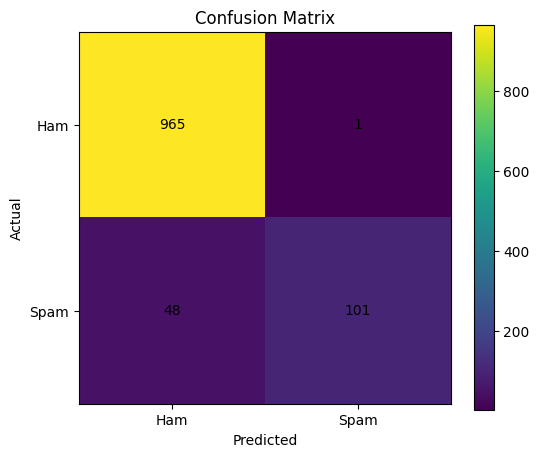

In [25]:
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["Ham", "Spam"])
plt.yticks([0, 1], ["Ham", "Spam"])
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )
plt.colorbar()
plt.show()

In [27]:
from sklearn.metrics import confusion_matrix

y_prob = sigmoid(X_test.dot(weights) + bias)

thresholds = np.arange(0.1, 1.0, 0.05)

tpr_values = []
fpr_values = []

for threshold in thresholds:
    y_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_threshold
    ).ravel()

    tpr = tp / (tp + fn) if (tp + fn) != 0 else 0
    fpr = fp / (fp + tn) if (fp + tn) != 0 else 0

    tpr_values.append(tpr)
    fpr_values.append(fpr)

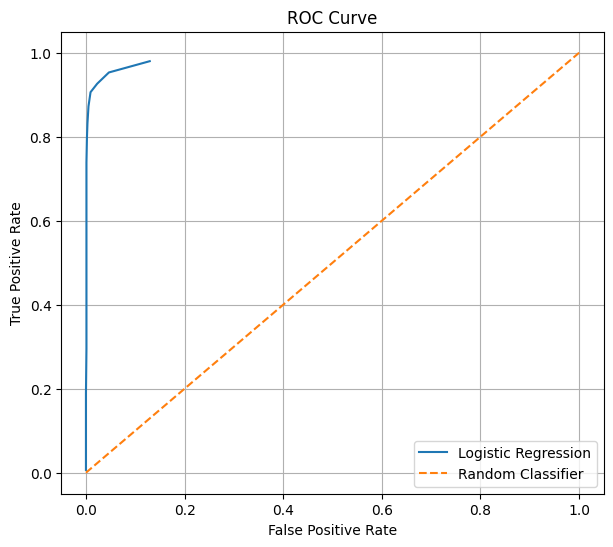

In [28]:
plt.figure(figsize=(7, 6))
plt.plot(
    fpr_values,
    tpr_values,
    label="Logistic Regression"
)
plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random Classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [29]:
threshold_list = [0.3, 0.5, 0.7]
results = []
for threshold in threshold_list:
    y_threshold = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_threshold
    ).ravel()
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0

    f1 = (
        2 * precision * recall /
        (precision + recall)
        if (precision + recall) != 0
        else 0
    )
    results.append([
        threshold,
        precision,
        recall,
        f1
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "Precision",
        "Recall",
        "F1-score"
    ]
)
print(results_df)

   Threshold  Precision    Recall  F1-score
0        0.3   0.962963  0.872483  0.915493
1        0.5   0.990196  0.677852  0.804781
2        0.7   0.982759  0.382550  0.550725


In [30]:
thresholds = np.linspace(0.01, 0.99, 99)
precision_values = []
recall_values = []
for Threshold in thresholds:
    y_threshold = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_threshold
    ).ravel()
    precision = (
        tp / (tp + fp)
        if (tp + fp) != 0
        else 0
    )
    recall = (
        tp / (tp + fn)
        if (tp + fn) != 0
        else 0
    )
    precision_values.append(precision)
    recall_values.append(recall)

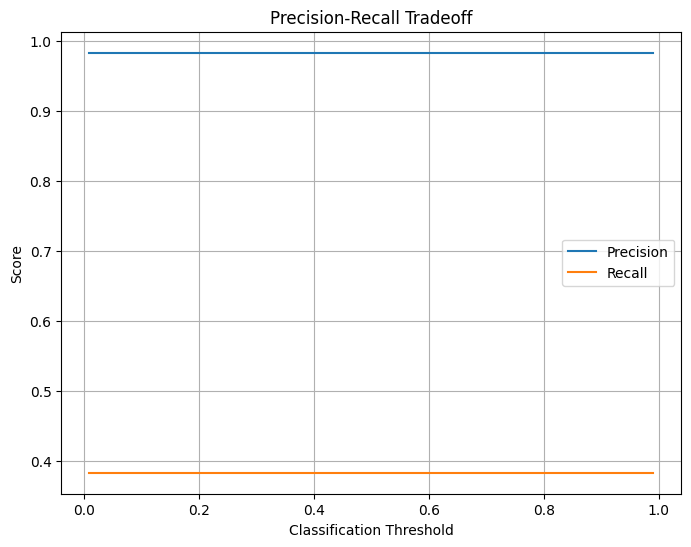

In [31]:
plt.figure(figsize=(8, 6))
plt.plot(
    thresholds,
    precision_values,
    label="Precision"
)
plt.plot(
    thresholds,
    recall_values,
    label="Recall"
)
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Tradeoff")
plt.legend()
plt.grid()
plt.show()

In [32]:
print(results_df)

   Threshold  Precision    Recall  F1-score
0        0.3   0.962963  0.872483  0.915493
1        0.5   0.990196  0.677852  0.804781
2        0.7   0.982759  0.382550  0.550725


In [33]:
thresholds = np.arange(0.1, 1.0, 0.1)
best_threshold = 0
best_f1 = 0
for threshold in thresholds:
    y_threshold = (y_prob >= threshold).astype(int)
    TP = TN = FP = FN = 0
    for actual, predicted in zip(y_test, y_threshold):
        if actual == 1 and predicted == 1:
            TP += 1
        elif actual == 0 and predicted == 0:
            TN += 1
        elif actual == 0 and predicted == 1:
            FP += 1
        elif actual == 1 and predicted == 0:
            FN += 1
    precision = TP / (TP + FP) if (TP + FP) != 0 else 0
    recall = TP / (TP + FN) if (TP + FN) != 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) != 0
        else 0
    )
    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold
print("\nOptimal Threshold:", best_threshold)
print("Best F1-score:", best_f1)

Threshold: 0.1 | Precision: 0.539 | Recall: 0.980 | F1: 0.695
Threshold: 0.2 | Precision: 0.863 | Recall: 0.926 | F1: 0.893
Threshold: 0.3 | Precision: 0.963 | Recall: 0.872 | F1: 0.915
Threshold: 0.4 | Precision: 0.983 | Recall: 0.799 | F1: 0.881
Threshold: 0.5 | Precision: 0.990 | Recall: 0.678 | F1: 0.805
Threshold: 0.6 | Precision: 0.988 | Recall: 0.550 | F1: 0.707
Threshold: 0.7 | Precision: 0.983 | Recall: 0.383 | F1: 0.551
Threshold: 0.8 | Precision: 1.000 | Recall: 0.188 | F1: 0.316
Threshold: 0.9 | Precision: 1.000 | Recall: 0.040 | F1: 0.077

Optimal Threshold: 0.30000000000000004
Best F1-score: 0.9154929577464789
